# 021 Final classifiers: one CLAM-MB per label set

**Overview.** One CLAM-MB is trained for each of three coarser label sets derived from the seven BRACS classes, and each is evaluated once on the official Testing set. The architecture, the optimiser and the regularisation are the setting selected by cross-validation in `02_vectors_to_classifier.ipynb`; no choice is made here, so the Testing set is used for reporting only.

```mermaid
flowchart TD
    subgraph IN["Inputs"]
        FEAT[("FEATURES_DIR/UNI2-h/<br/>one .pt file per slide (from 01)")]
        LAB[("labels/BRACS.xlsx<br/>class, patient, official set")]
    end

    subgraph S3["3. Data"]
        D1["3.1 build_slide_table + load_bags"]
        D2["3.2 make_holdout_split<br/>fit / early stopping (patient-grouped)"]
        D3["3.3 relabel_table<br/>three label sets"]
    end

    subgraph S4["4. Training (one CLAM-MB per label set)"]
        T1["train_final<br/>constants fixed from 02"]
        T2["plot_training_curves"]
    end

    subgraph S5["5. Evaluation (Testing set, used once)"]
        E1["predict_testing"]
        E2["class_views + bootstrap_views<br/>accuracy, F1, recall, precision,<br/>sensitivity, specificity, AUROC"]
        E3["plot_final_results<br/>confusion matrix + ROC"]
    end

    OUT[("classifier/final/label set/<br/>classifier_model_date-time.pt")]

    FEAT --> D1
    LAB --> D1
    D1 --> D2
    D2 --> D3
    D3 --> T1
    T1 --> T2
    T1 --> E1
    E1 --> E2
    E1 --> E3
    T1 --> OUT
```

## 1. Setup

The environment is recorded so the run can be reproduced.

In [1]:
# STEP 1: Import general-purpose third-party libraries
import sys
import matplotlib
import numpy as np
import pandas as pd
import sklearn
import torch

# STEP 2: Print library versions for reproducibility
print('System Version:', sys.version)
print('PyTorch version:', torch.__version__)
print('Scikit-learn version:', sklearn.__version__)
print('Numpy version:', np.__version__)
print('Pandas version:', pd.__version__)
print('Matplotlib version:', matplotlib.__version__)

System Version: 3.14.7 (main, Aug 10 2026, 07:46:56) [GCC 16.1.1 20260728]
PyTorch version: 2.15.0+cu132
Scikit-learn version: 1.9.1
Numpy version: 2.5.4
Pandas version: 3.1.1
Matplotlib version: 3.11.2


The model is trained on the GPU when one is available and on the CPU otherwise (`utils.device.get_device`).

In [2]:
# STEP 1: Select the device (pass e.g. get_device("cpu") to force the CPU)
from utils.device import get_device
DEVICE = get_device()

# STEP 2: Report it
print('Device:', DEVICE, '|', torch.cuda.get_device_name(DEVICE) if DEVICE.type == 'cuda' else 'no GPU, running on the CPU')

Device: cuda | NVIDIA RTX PRO 4500 Blackwell


The project's own building blocks are imported here. The data, model and training code is shared with notebook 02; the code specific to this notebook is in `utils/final_classifier.py`.

In [3]:
# STEP 1: Standard-library imports
from pathlib import Path
from time import time

# STEP 2: Import this project's own building blocks
from utils.dataset_overview import build_slide_table
from utils.mil_data import load_bags
from utils.mil_train import device_description, predict_ensemble, save_best_model, set_seed, training_class_weights
from utils.classification_metrics import evaluate_predictions
from utils.plot_classification import plot_training_curves
from utils.final_classifier import (bootstrap_views, cascade_predict, class_views, combine_two_stage, format_differences, format_views, make_holdout_split,
                                    make_stage2_table, paired_bootstrap_views, plot_final_results, predict_testing, relabel_table, summary_across_sets, train_final)

## 2. Constants

Every setting is defined here. The training settings are those selected by patient-grouped cross-validation in notebook 02 for CLAM-MB (section 5: loss weighting 5.1, regularisation 5.2); the coarse auxiliary loss of section 5.3 is not used, because it is defined on the seven classes. Each label set is a mapping from the seven BRACS classes to a group; the order of the groups is the order of the model outputs, so the last group of the binary set (Cancer) is its positive class.

In [4]:
# Major variables
FEATURES_DIR = Path('/mnt/Scratch/phd_streamembed_features/level_1')   # STEP 1: Folder with one subfolder of .pt files per model
MODEL_NAME = 'UNI2-h'                                           # STEP 2: Subfolder with the per-slide features
LABELS_FILE = Path('labels/BRACS.xlsx')                          # STEP 3: Slide labels, patients and official split
MODEL_DIR = Path('classifier/final')                             # STEP 4: Folder of the saved classifiers (one subfolder per label set)
SAVE_MODELS = True                                               # STEP 5: Save one classifier per label set as classifier_model_<date-time>.pt
SEED = 0                                                         # STEP 6: Seed of every random choice
EARLY_STOP_FRACTION = 0.2                                        # STEP 7: Share of Training + Validation used to pick the epoch (patient-grouped)
EPOCHS, PATIENCE = 100, 5                                        # STEP 8: Maximum epochs; early-stopping patience (epochs without a better macro F1, counted after the warm-up)
LR, WEIGHT_DECAY = 2e-4, 1e-1                                    # STEP 9: Peak learning rate and AdamW weight decay (the value selected in 02)
BATCH_SIZE, MAX_TILES_TRAIN = 16, 2048                           # STEP 10: Slides per batch, tiles per slide in training
MODEL_ARGS = dict(k_sample=8, bag_weight=0.7)                    # STEP 11: CLAM-MB: tiles per instance-loss group, weight of the slide loss
DROPOUT, TILE_DROPOUT = 0.25, 0.5                                # STEP 12: Dropout rate and share of the tiles removed from a training bag (selected in 02)
WEIGHTING = 'sqrt'                                               # STEP 13: Class weighting of the loss, from the fit slides (selected in 02)
N_BOOT = 1000                                                    # STEP 14: Bootstrap resamples (patients) for the intervals
LABEL_SETS = {                                                   # STEP 15: The label sets: {name: {BRACS class: group}}
    'Benign / Atypical / Malignant': {'N': 'Benign', 'PB': 'Benign', 'UDH': 'Benign', 'FEA': 'Atypical', 'ADH': 'Atypical', 'DCIS': 'Malignant', 'IC': 'Malignant'},
    'Non-cancer / Cancer': {'N': 'Non-cancer', 'PB': 'Non-cancer', 'UDH': 'Non-cancer', 'FEA': 'Non-cancer', 'ADH': 'Non-cancer', 'DCIS': 'Cancer', 'IC': 'Cancer'},
    'Non-cancer / DCIS / IC': {'N': 'Non-cancer', 'PB': 'Non-cancer', 'UDH': 'Non-cancer', 'FEA': 'Non-cancer', 'ADH': 'Non-cancer', 'DCIS': 'DCIS', 'IC': 'IC'},
}
set_seed(SEED)
TRAIN_ARGS = dict(epochs=EPOCHS, patience=PATIENCE, lr=LR, weight_decay=WEIGHT_DECAY, batch_size=BATCH_SIZE, max_tiles=MAX_TILES_TRAIN)

## 3. Data

### 3.1 Slides and tile embeddings

The slide table holds the official split of BRACS. The bags of tile embeddings (UNI2-h CLS tokens) are loaded once and shared by the three label sets.

In [5]:
# STEP 1: Label table with the official split and the bags of tile embeddings (float16)
table = build_slide_table(LABELS_FILE)
data = load_bags(FEATURES_DIR, MODEL_NAME, table)

Loading bags:   0%|          | 0/547 [00:00<?, ?it/s]

Slides with features: 546 of 547  |  tiles 1,457,195  |  tiles per slide: median 2377, min 2, max 8962  |  dim 1536
Per set (with features / labelled): Training 395/395, Validation 64/65, Testing 87/87
Dropped: 1 without a feature file, 0 without tiles (e.g. ['BRACS_1003660'])
Tiling in the files: level 2, tile 224, stride 224


### 3.2 Fit and early-stopping slides

The official Training and Validation slides are pooled and split once into fit slides and early-stopping slides, grouped by patient and stratified on the seven classes. Because the split uses the seven-class label, the three label sets are trained and stopped on exactly the same slides, and the official Testing slides are untouched.

In [6]:
# STEP 1: One split for all label sets (the real Testing slides stay "Testing")
split = make_holdout_split(data['table'], EARLY_STOP_FRACTION, SEED)

# STEP 2: Slides and patients per part
split.groupby('set').agg(slides=('slide', 'size'), patients=('patient', 'nunique')).rename(index={'Training': 'Training (fit)', 'Validation': 'Validation (early stopping)'})

,slides,patients
set,,
Training (fit),367,124
Validation (early stopping),92,34
Testing,87,31


### 3.3 The label sets

Slides per group and part for each label set. Groups are unbalanced in all three sets, which is why the loss is class-weighted; the weights are computed from the fit slides only.

In [7]:
# STEP 1: Relabel the split for every label set
tables, class_lists = {}, {}
for name, mapping in LABEL_SETS.items():
    tables[name], class_lists[name] = relabel_table(split, mapping)

# STEP 2: Slides per group and part
pd.concat({name: pd.crosstab(t['label'], t['set']).reindex(class_lists[name])[['Training', 'Validation', 'Testing']] for name, t in tables.items()})

set                                       Training  Validation  Testing
                              label                                    
Benign / Atypical / Malignant Benign           186          46       32
                              Atypical          52          14       23
                              Malignant        129          32       32
Non-cancer / Cancer           Non-cancer       238          60       55
                              Cancer           129          32       32
Non-cancer / DCIS / IC        Non-cancer       238          60       55
                              DCIS              39          10       12
                              IC                90          22       20

## 4. Training

One CLAM-MB is trained per label set with the constants of section 2. The loss of every model is the class-weighted cross-entropy (weights from its own fit slides), for training and for the early-stopping slides alike. The epoch with the highest macro F1 on the early-stopping slides is kept (macro F1 gives every class the same weight; ties are broken by the class-weighted early-stopping loss); the Testing labels are not read inside `train_model`.

In [8]:
# STEP 1: Train one model per label set
runs = {}
for name in LABEL_SETS:
    t0 = time()
    runs[name] = train_final(data, tables[name], class_lists[name], DEVICE, SEED, WEIGHTING, MODEL_ARGS, TRAIN_ARGS, DROPOUT, TILE_DROPOUT, verbose=False)
    run = runs[name]
    print(f"{name}: best epoch {run['best_epoch']} of {run['epochs_run']}, early-stopping macro F1 {run['best']['val_macro_f1']:.3f}, balanced accuracy {run['best']['val_balanced_accuracy']:.3f}  ({time() - t0:.0f} s)")

Benign / Atypical / Malignant: best epoch 6 of 11, early-stopping macro F1 0.706, balanced accuracy 0.695  (14 s)
Non-cancer / Cancer: best epoch 9 of 14, early-stopping macro F1 0.928, balanced accuracy 0.928  (16 s)
Non-cancer / DCIS / IC: best epoch 9 of 14, early-stopping macro F1 0.892, balanced accuracy 0.911  (17 s)


### 4.1 Training curves

Training loss and early-stopping loss (both class-weighted) and early-stopping macro F1 of each model over the epochs; the marker is the epoch that was kept.

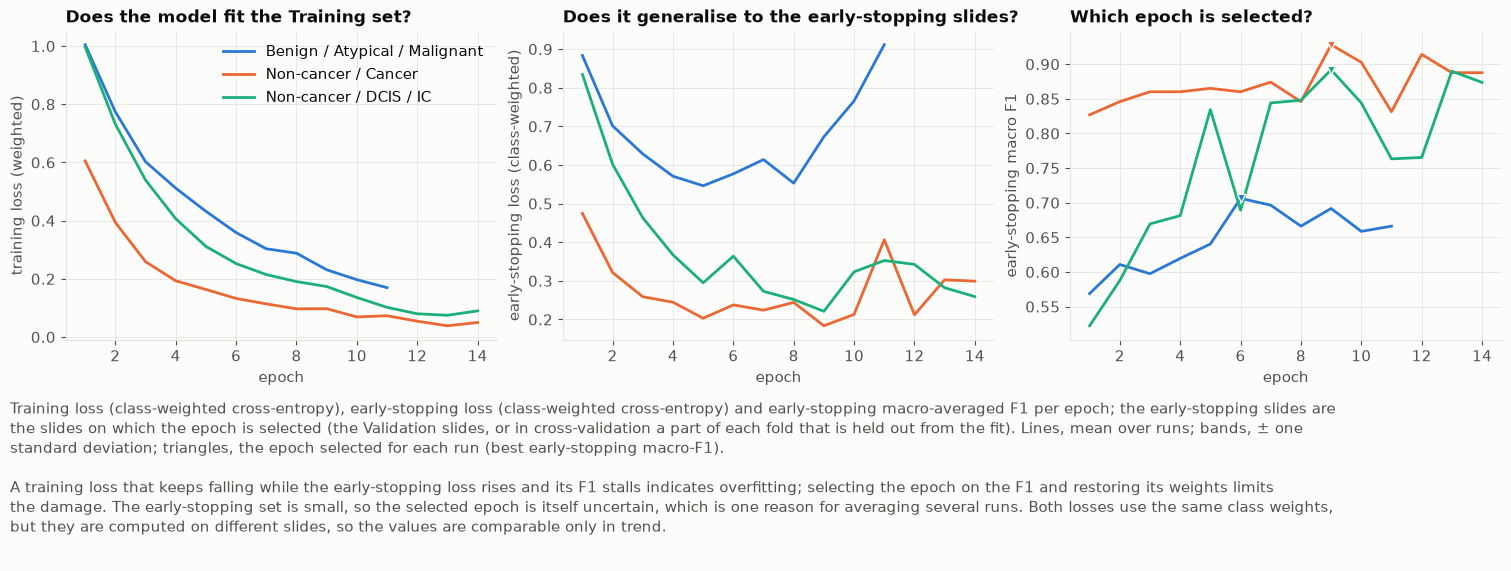

In [9]:
# STEP 1: The curves of every label set
curves = plot_training_curves({name: [run['history']] for name, run in runs.items()}, weighted_val_loss=True)

## 5. Evaluation on the Testing set

The Testing labels are read here for the first time. The probabilities of each model give the predicted class (the highest probability), from which the confusion matrix, accuracy, F1, sensitivity (recall), specificity and precision follow, and the ROC curve and AUROC use the probabilities directly. For more than two classes each measure is computed one class against the rest and averaged over classes (macro); for the binary set the Cancer row is the usual binary view. The 95% intervals come from a bootstrap that resamples patients.

In [10]:
# STEP 1: Predictions on the Testing slides
predictions = {name: predict_testing(runs[name], data, tables[name], class_lists[name], DEVICE) for name in LABEL_SETS}

# STEP 2: All measures, with patient-bootstrap intervals
evaluations = {n: evaluate_predictions(p['y'], p['proba'], class_lists[n]) for n, p in predictions.items()}
views = {n: class_views(p['y'], p['proba'], class_lists[n]) for n, p in predictions.items()}
intervals = {n: bootstrap_views(p['y'], p['proba'], p['patients'], class_lists[n], N_BOOT, SEED) for n, p in predictions.items()}
print({n: f"{len(p['y'])} slides, {len(set(p['patients']))} patients" for n, p in predictions.items()})

{'Benign / Atypical / Malignant': '87 slides, 31 patients', 'Non-cancer / Cancer': '87 slides, 31 patients', 'Non-cancer / DCIS / IC': '87 slides, 31 patients'}


### 5.1 Confusion matrices and ROC curves

One figure per label set: the confusion matrix and the one-vs-rest ROC curves with their AUROC.

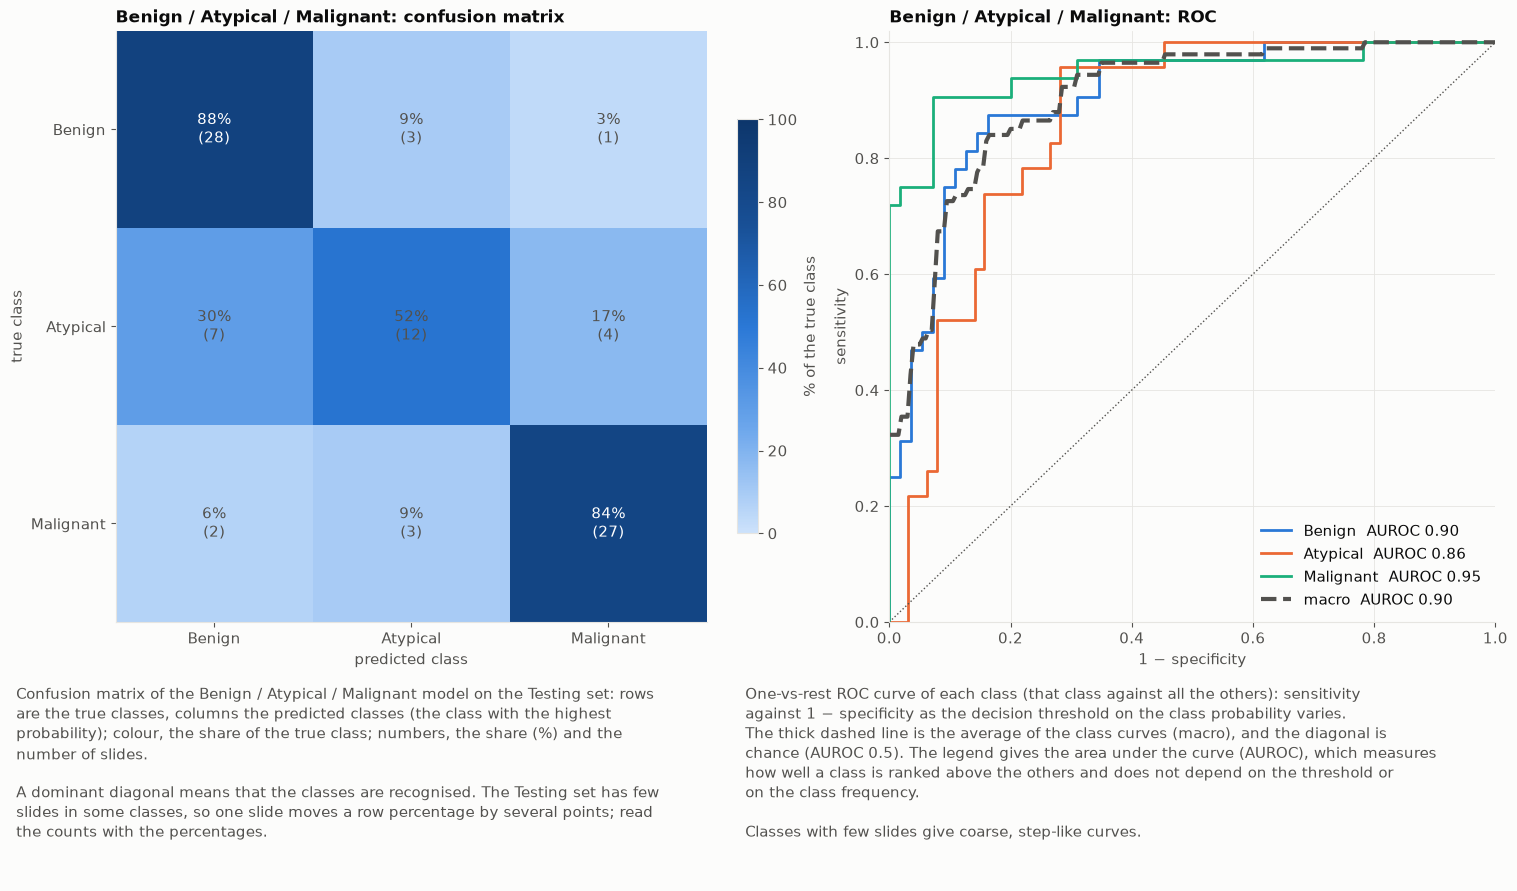

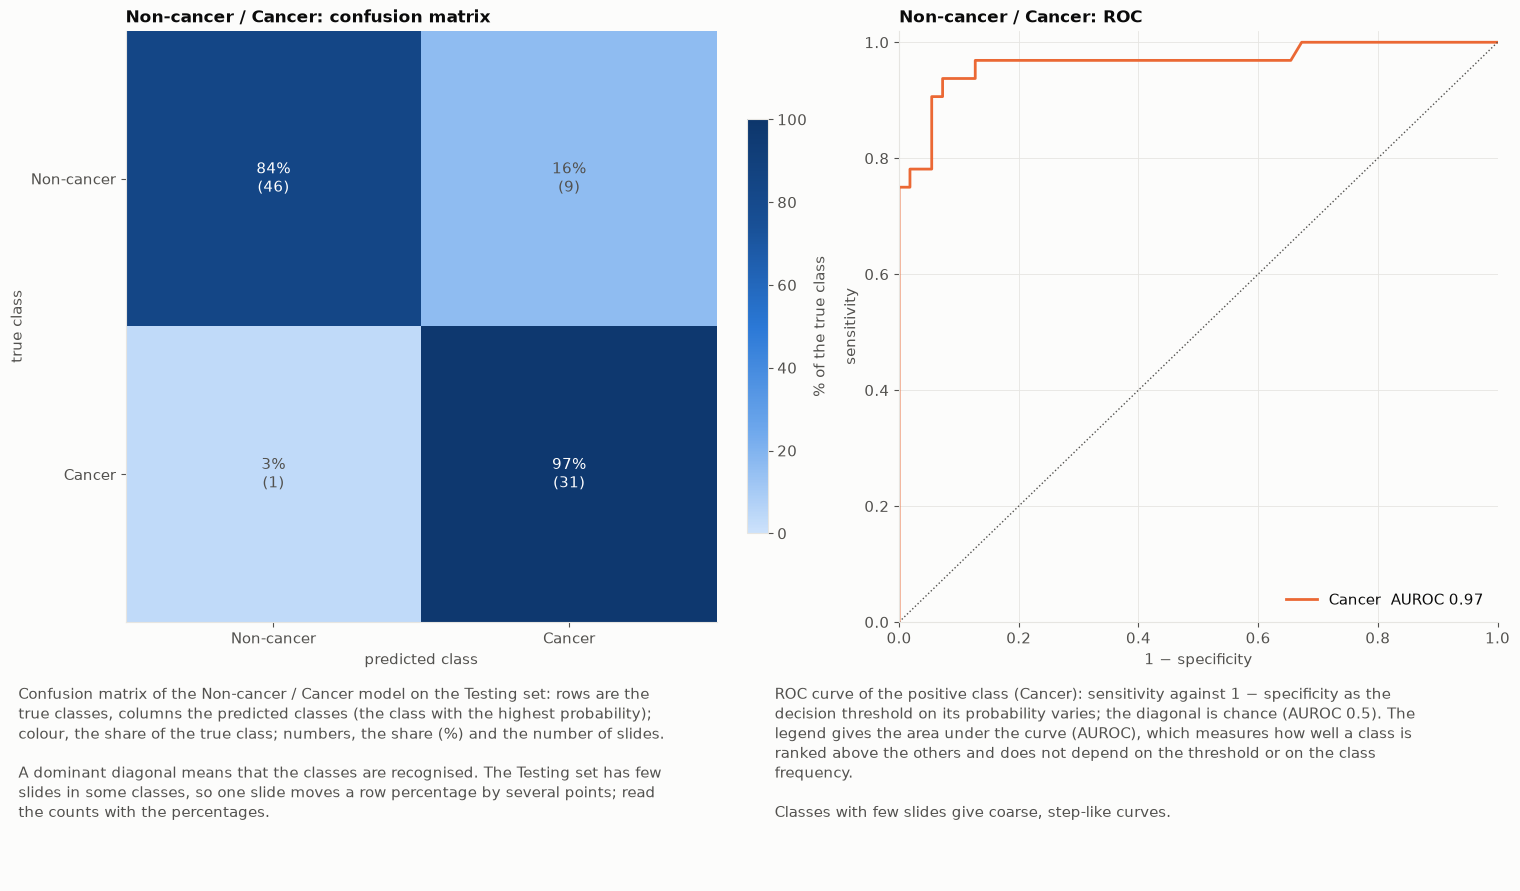

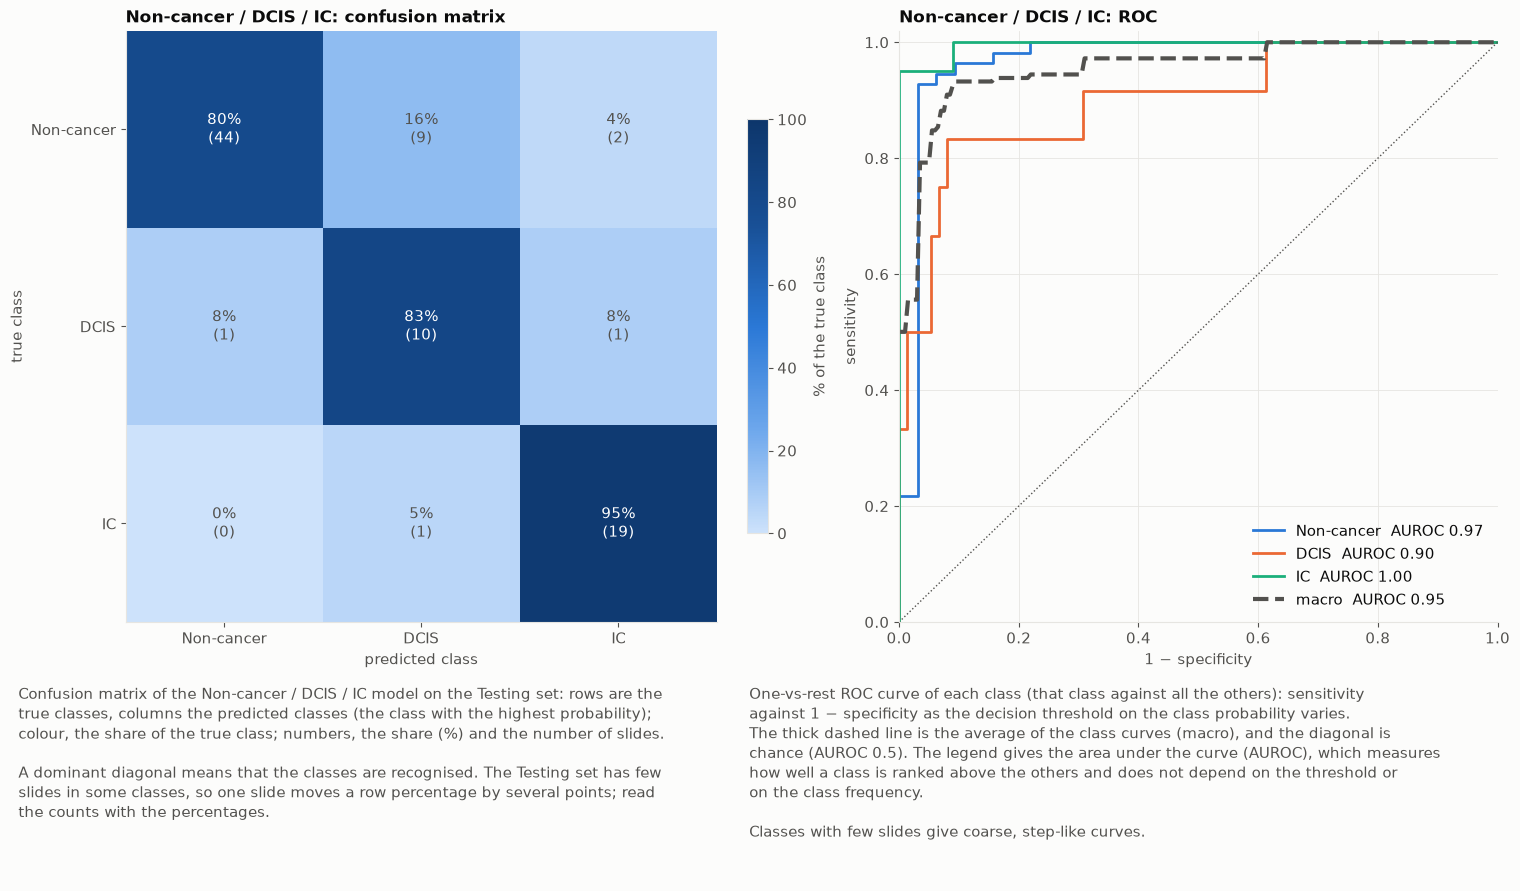

In [11]:
# STEP 1: One figure per label set
figures = {name: plot_final_results(name, evaluations[name]['confusion'], predictions[name]['y'], predictions[name]['proba'], class_lists[name]) for name in LABEL_SETS}

### 5.2 Measures per class

Accuracy, sensitivity (recall), specificity, precision, F1 and AUROC of each class against the rest, with the 95% patient-bootstrap interval. The accuracy of a class row is its one-vs-rest accuracy; the `macro` row has the multi-class accuracy and the unweighted mean of the other measures over classes. Sensitivity is the recall of the class and specificity is the share of the other classes correctly not assigned to it. A measure with a wide interval rests on few slides.

In [12]:
# STEP 1: One table per label set
for name in LABEL_SETS:
    print(name)
    display(format_views(views[name], intervals[name]))

Benign / Atypical / Malignant


,accuracy,sensitivity,specificity,precision,f1,auroc
Benign,"0.851 [0.766, 0.932]","0.875 [0.794, 1.000]","0.836 [0.706, 0.935]","0.757 [0.556, 0.891]","0.812 [0.682, 0.902]","0.903 [0.810, 0.969]"
Atypical,"0.805 [0.734, 0.880]","0.522 [0.267, 0.735]","0.906 [0.836, 0.981]","0.667 [0.526, 0.857]","0.585 [0.370, 0.717]","0.860 [0.785, 0.932]"
Malignant,"0.885 [0.794, 0.961]","0.844 [0.657, 0.974]","0.909 [0.789, 0.982]","0.844 [0.690, 0.966]","0.844 [0.692, 0.945]","0.948 [0.880, 0.994]"
macro,"0.770 [0.680, 0.859]","0.747 [0.670, 0.824]","0.884 [0.837, 0.926]","0.756 [0.678, 0.837]","0.747 [0.649, 0.825]","0.904 [0.845, 0.952]"


Non-cancer / Cancer


,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"0.885 [0.788, 0.963]","0.836 [0.684, 0.944]","0.969 [0.889, 1.000]","0.979 [0.921, 1.000]","0.902 [0.795, 0.970]","0.966 [0.910, 0.998]"
Cancer,"0.885 [0.788, 0.963]","0.969 [0.889, 1.000]","0.836 [0.684, 0.944]","0.775 [0.630, 0.912]","0.861 [0.750, 0.952]","0.966 [0.910, 0.998]"
macro,"0.885 [0.788, 0.963]","0.903 [0.812, 0.970]","0.903 [0.812, 0.970]","0.877 [0.789, 0.955]","0.882 [0.781, 0.959]","0.966 [0.910, 0.998]"


Non-cancer / DCIS / IC


,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"0.862 [0.756, 0.954]","0.800 [0.632, 0.933]","0.969 [0.889, 1.000]","0.978 [0.918, 1.000]","0.880 [0.760, 0.964]","0.968 [0.911, 1.000]"
DCIS,"0.862 [0.768, 0.951]","0.833 [0.600, 1.000]","0.867 [0.760, 0.959]","0.500 [0.333, 0.737]","0.625 [0.444, 0.800]","0.900 [0.775, 0.982]"
IC,"0.954 [0.897, 0.989]","0.950 [0.833, 1.000]","0.955 [0.887, 1.000]","0.864 [0.667, 1.000]","0.905 [0.759, 0.980]","0.996 [0.983, 1.000]"
macro,"0.839 [0.737, 0.936]","0.861 [0.760, 0.946]","0.930 [0.878, 0.974]","0.780 [0.689, 0.872]","0.803 [0.705, 0.890]","0.955 [0.896, 0.992]"


### 5.3 Comparison of the label sets

The macro row of each label set. The sets differ in the number of classes, so accuracy and F1 are not directly comparable across them: chance level is higher with fewer classes. For the binary set the macro row averages the Non-cancer and Cancer rows; the Cancer row of the table above is the positive-class view.

In [13]:
# STEP 1: Macro measures of the three models
summary_across_sets(views).round(3)

,accuracy,sensitivity,specificity,precision,f1,auroc
Benign / Atypical / Malignant,0.770,0.747,0.884,0.756,0.747,0.904
Non-cancer / Cancer,0.885,0.903,0.903,0.877,0.882,0.966
Non-cancer / DCIS / IC,0.839,0.861,0.930,0.780,0.803,0.955


## 6. Save

One classifier per label set is written to its own subfolder, in the format of `save_best_model` (weights, class names, feature scaler, architecture settings and configuration), so each can be loaded with `mil_train.load_classifier`.

In [14]:
# STEP 1: What is needed to reproduce and to reuse each run
config = dict(
    seed=SEED, early_stop_fraction=EARLY_STOP_FRACTION, model_args=MODEL_ARGS, weighting=WEIGHTING, train_args=TRAIN_ARGS, dropout=DROPOUT, tile_dropout=TILE_DROPOUT, n_boot=N_BOOT,
    features_dir=str(FEATURES_DIR), model_name=MODEL_NAME, tile_params=data['tile_params'], device=device_description(DEVICE), label_sets=LABEL_SETS,
    versions=dict(torch=torch.__version__, sklearn=sklearn.__version__, numpy=np.__version__, pandas=pd.__version__), dropped_slides=data['missing'],
)

# STEP 2: Save one classifier per label set
if SAVE_MODELS:
    for name, run in runs.items():
        slug = name.lower().replace(' / ', '_').replace('-', '')
        path = save_best_model({'clam_mb': [run]}, MODEL_DIR / slug, {**config, 'label_set': name, 'classes': class_lists[name]})
        print(f'{name}: saved to', path.resolve())
else:
    print('SAVE_MODELS is False: nothing was written.')

Benign / Atypical / Malignant: saved to /home/guisazevedo/Projects/01_accamargo/phd_streamembed/classifier/final/benign_atypical_malignant/classifier_model_2026-11-10_11-31-51.pt
Non-cancer / Cancer: saved to /home/guisazevedo/Projects/01_accamargo/phd_streamembed/classifier/final/noncancer_cancer/classifier_model_2026-11-10_11-31-51.pt
Non-cancer / DCIS / IC: saved to /home/guisazevedo/Projects/01_accamargo/phd_streamembed/classifier/final/noncancer_dcis_ic/classifier_model_2026-11-10_11-31-51.pt


## 7. Two-stage classifier: Cancer first, then DCIS or IC

The flat Non-cancer / DCIS / IC model of section 4 has to separate three classes at once, and its weakest class is DCIS (low precision). The hierarchical alternative uses the Non-cancer / Cancer model of section 4 as the first stage and a second model, trained only on cancer slides (DCIS and IC), as the second stage. The decision is a cascade: a slide that the first stage assigns to Non-cancer is final, and only the slides that the first stage assigns to Cancer are divided between DCIS and IC by the second stage. The Non-cancer class is therefore decided by the first stage alone, and its measures in this section equal those of the Non-cancer / Cancer model.

Two properties limit what the hierarchy can achieve. The errors of the first stage are inherited: a non-cancer slide that passes the first stage is necessarily labelled DCIS or IC, so the false positives of the Cancer model (its precision is below 1) cannot be corrected by the second stage. And the second stage is trained on few slides (listed below), so its epoch selection is noisy. Whether the hierarchy improves on the flat model is therefore judged on the paired bootstrap of section 8.

### 7.1 Cancer-only model (stage 2)

The second stage is a CLAM-MB trained on the DCIS and IC slides only, with the same split, the same settings and the same class-weighted loss as the other models. The class weights are computed from the fit slides of this model (DCIS and IC) and weight the training loss and the early-stopping loss alike; the Testing slides are not in its table. The table lists the slides it uses, and the weights it trains with are printed.

set,Training,Validation
label,,
DCIS,39,10
IC,90,22


Class weights (sqrt) of the cancer-only model: {'DCIS': np.float32(1.313), 'IC': np.float32(0.864)}
DCIS / IC (stage 2): best epoch 7 of 12, early-stopping macro F1 0.963, balanced accuracy 0.950  (5 s)


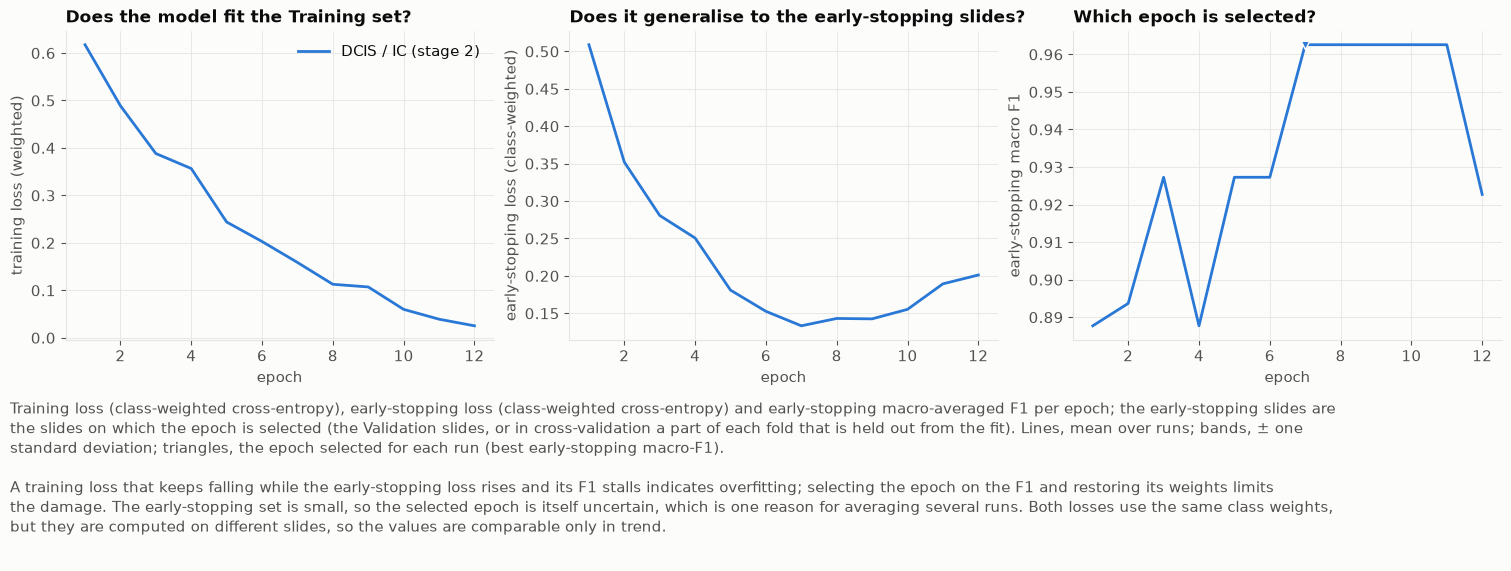

In [15]:
# STEP 1: The second-stage classes (the cancer slides only; the Testing slides are dropped from this table)
STAGE2_MAPPING = {'DCIS': 'DCIS', 'IC': 'IC'}
table2, classes2 = make_stage2_table(split, STAGE2_MAPPING)
assert 'Testing' not in set(table2['set'])

# STEP 2: Slides per class and part
display(pd.crosstab(table2['label'], table2['set']).reindex(classes2)[['Training', 'Validation']])

# STEP 3: The class weights of this model (from its fit slides); the loss is never unweighted
assert WEIGHTING is not None
weights2 = training_class_weights({**data, 'table': table2, 'classes': classes2}, WEIGHTING)
print(f"Class weights ({WEIGHTING}) of the cancer-only model:", dict(zip(classes2, weights2.numpy().round(3))))

# STEP 4: Train the second-stage model with the constants of section 2
t0 = time()
run2 = train_final(data, table2, classes2, DEVICE, SEED, WEIGHTING, MODEL_ARGS, TRAIN_ARGS, DROPOUT, TILE_DROPOUT, verbose=False)
print(f"DCIS / IC (stage 2): best epoch {run2['best_epoch']} of {run2['epochs_run']}, early-stopping macro F1 {run2['best']['val_macro_f1']:.3f}, balanced accuracy {run2['best']['val_balanced_accuracy']:.3f}  ({time() - t0:.0f} s)")

# STEP 5: Training curves (class-weighted training and early-stopping loss)
curves2 = plot_training_curves({'DCIS / IC (stage 2)': [run2['history']]}, weighted_val_loss=True)

### 7.2 Cascade decisions and confusion matrix

Both stages are applied to every Testing slide. The predicted class follows the cascade: Non-cancer if the first stage assigns the slide to Non-cancer, otherwise the class with the highest probability of the second stage. The slides are distributed over the 3 × 3 confusion matrix with these decisions, and accuracy, sensitivity, specificity, precision and F1 are computed from that matrix.

The AUROC and the ROC curves need a continuous score for each class and use the chain rule, P(DCIS) = P(Cancer) · P(DCIS | cancer) and likewise for IC, with P(Non-cancer) from the first stage. The argmax of these products is not used as the decision: when the second stage is undecided, the cancer probability is split between DCIS and IC and each can fall below P(Non-cancer), which would send a slide that the first stage calls Cancer back to Non-cancer. The assertion below checks that the cascade never does so.

In [16]:
# STEP 1: The same Testing slides, in the same order, for both stages and for the flat model
FLAT, BINARY = 'Non-cancer / DCIS / IC', 'Non-cancer / Cancer'
slides = predictions[FLAT]['test']['slide'].tolist()
assert slides == predictions[BINARY]['test']['slide'].tolist()
proba_binary = predictions[BINARY]['proba']

# STEP 2: Second-stage probabilities of every Testing slide, the cascade decisions and the scores for the ROC
proba2 = predict_ensemble([run2], data, slides, DEVICE)['proba']
pred_two = cascade_predict(proba_binary, proba2)
score_two = combine_two_stage(proba_binary, proba2)
assert ((pred_two == 0) == (proba_binary.argmax(1) == 0)).all(), 'Non-cancer must be decided by the first stage alone'

# STEP 3: Confusion matrix of the cascade decisions (rows true class, columns predicted class)
TWO = 'Two-stage: Non-cancer / Cancer, then DCIS / IC'
y_two, K = predictions[FLAT]['y'], len(class_lists[FLAT])
confusion_two = pd.DataFrame(np.bincount(y_two * K + pred_two, minlength=K * K).reshape(K, K), index=class_lists[FLAT], columns=class_lists[FLAT])
confusion_two.index.name, confusion_two.columns.name = 'true', 'predicted'
display(confusion_two)

# STEP 4: The measures from the cascade decisions (AUROC from the scores), in the layout of the other models
predictions[TWO] = {**predictions[FLAT], 'proba': score_two, 'pred': pred_two}
class_lists[TWO] = class_lists[FLAT]
views[TWO] = class_views(y_two, score_two, class_lists[TWO], pred_two)
intervals[TWO] = bootstrap_views(y_two, score_two, predictions[TWO]['patients'], class_lists[TWO], N_BOOT, SEED, pred_two)

# STEP 5: The Non-cancer row must equal that of the Non-cancer / Cancer model (its measures, read for Non-cancer)
for measure in ['sensitivity', 'specificity', 'precision']:
    assert np.isclose(views[TWO].loc['Non-cancer', measure], views[BINARY].loc['Non-cancer', measure]), measure
print('Non-cancer row identical to the Non-cancer / Cancer model: sensitivity', round(views[TWO].loc['Non-cancer', 'sensitivity'], 3))

predicted,Non-cancer,DCIS,IC
true,,,
Non-cancer,46,6,3
DCIS,1,9,2
IC,0,1,19


Non-cancer row identical to the Non-cancer / Cancer model: sensitivity 0.836


### 7.3 Confusion matrix, ROC and measures of the two-stage model

The figure and the table have the layout of section 5, on the same Testing slides and the same three classes, so they can be read directly against those of the flat model. The confusion matrix and the measures come from the cascade decisions; the ROC curves and the AUROC from the chain-rule scores.

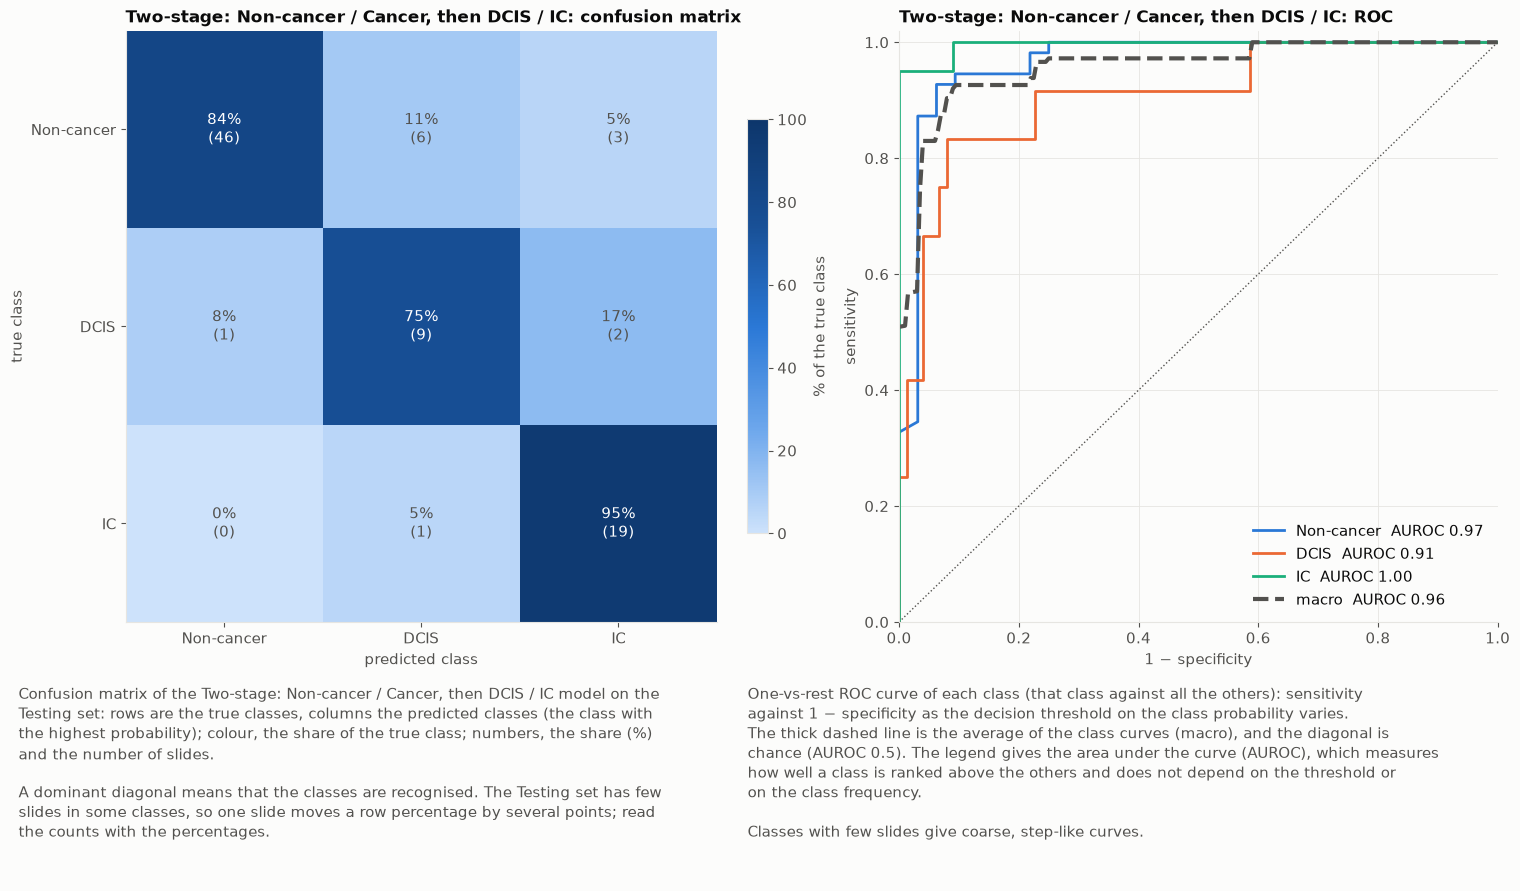

,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"0.885 [0.788, 0.963]","0.836 [0.684, 0.944]","0.969 [0.889, 1.000]","0.979 [0.921, 1.000]","0.902 [0.795, 0.970]","0.966 [0.910, 0.998]"
DCIS,"0.885 [0.800, 0.957]","0.750 [0.454, 1.000]","0.907 [0.820, 0.974]","0.562 [0.333, 0.790]","0.643 [0.381, 0.824]","0.908 [0.776, 0.990]"
IC,"0.931 [0.871, 0.978]","0.950 [0.833, 1.000]","0.925 [0.844, 0.979]","0.792 [0.615, 0.931]","0.864 [0.733, 0.955]","0.996 [0.982, 1.000]"
macro,"0.851 [0.747, 0.934]","0.845 [0.731, 0.937]","0.934 [0.882, 0.972]","0.778 [0.677, 0.871]","0.803 [0.693, 0.893]","0.956 [0.896, 0.993]"


In [17]:
# STEP 1: Confusion matrix (cascade decisions) and one-vs-rest ROC curves (chain-rule scores)
fig_two = plot_final_results(TWO, confusion_two, y_two, score_two, class_lists[TWO])

# STEP 2: Measures per class with patient-bootstrap intervals
display(format_views(views[TWO], intervals[TWO]))

### 7.4 The second stage on its own

To separate the quality of the second stage from the errors inherited from the first, the DCIS / IC model is evaluated on the Testing slides that are truly cancer (DCIS or IC) only. Any difference between this table and the DCIS and IC rows of section 7.3 is due to the first stage. The number of non-cancer slides that the first stage sends to the second is printed as well.

Non-cancer Testing slides passed to the second stage: 9 of 55


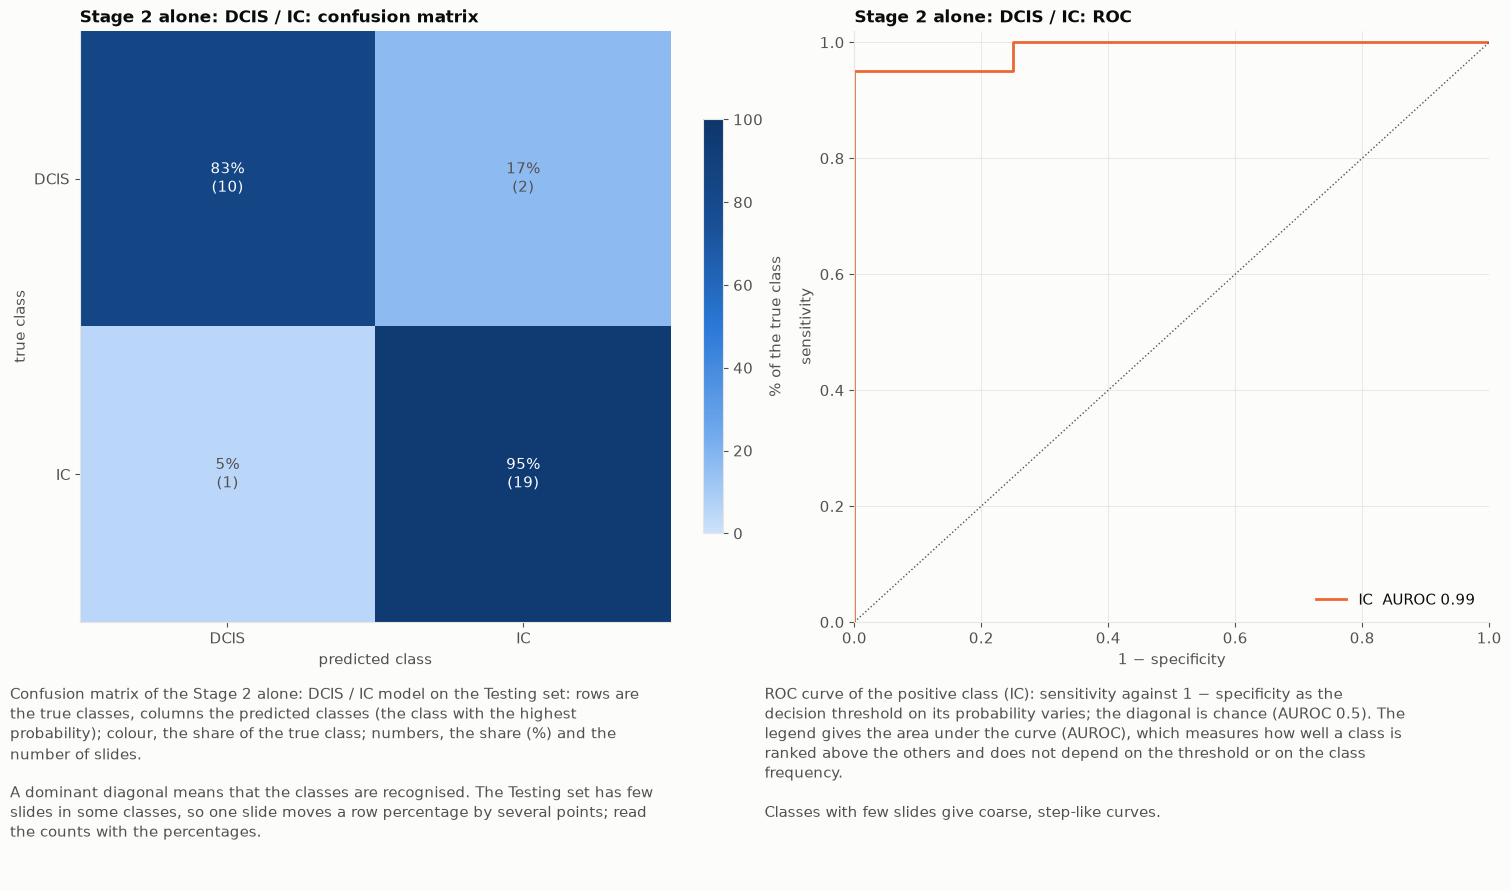

,accuracy,sensitivity,specificity,precision,f1,auroc
DCIS,"0.906 [0.800, 1.000]","0.833 [0.583, 1.000]","0.950 [0.812, 1.000]","0.909 [0.667, 1.000]","0.870 [0.667, 1.000]","0.987 [0.948, 1.000]"
IC,"0.906 [0.800, 1.000]","0.950 [0.812, 1.000]","0.833 [0.583, 1.000]","0.905 [0.762, 1.000]","0.927 [0.812, 1.000]","0.988 [0.948, 1.000]"
macro,"0.906 [0.800, 1.000]","0.892 [0.760, 1.000]","0.892 [0.760, 1.000]","0.907 [0.770, 1.000]","0.898 [0.762, 1.000]","0.988 [0.948, 1.000]"


In [18]:
# STEP 1: Truly cancer Testing slides (classes 1 and 2 of the 3-class labels) and their DCIS / IC labels
mask = y_two > 0
y2, p2, patients2 = y_two[mask] - 1, proba2[mask], predictions[TWO]['patients'][mask]

# STEP 2: Non-cancer slides that the first stage passes on as Cancer
passed = int(((y_two == 0) & (pred_two > 0)).sum())
print(f"Non-cancer Testing slides passed to the second stage: {passed} of {int((y_two == 0).sum())}")

# STEP 3: Confusion matrix, ROC and measures of the second stage
views2 = class_views(y2, p2, classes2)
intervals2 = bootstrap_views(y2, p2, patients2, classes2, N_BOOT, SEED)
fig2 = plot_final_results('Stage 2 alone: DCIS / IC', evaluate_predictions(y2, p2, classes2)['confusion'], y2, p2, classes2)
display(format_views(views2, intervals2))

## 8. Comparison with the flat model

The measures of the flat and of the two-stage model on the same Testing slides, followed by the difference (two-stage minus flat) with a 95% interval from a paired patient bootstrap, in which both models are scored on the same resamples. A difference whose interval contains zero is not distinguishable from no change at this sample size (87 slides, 31 patients); a class with few slides, such as DCIS (12 slides), changes by several points with a single slide.

In [19]:
# STEP 1: Macro measures and the DCIS row of both models
display(summary_across_sets({'Flat': views[FLAT], 'Two-stage': views[TWO]}).round(3))
display(pd.DataFrame({'Flat': views[FLAT].loc['DCIS'], 'Two-stage': views[TWO].loc['DCIS']}).T.round(3))

# STEP 2: Paired patient bootstrap of the difference (two-stage minus flat), per class and macro
proba_flat = predictions[FLAT]['proba']
differences = paired_bootstrap_views(y_two, score_two, pred_two, proba_flat, proba_flat.argmax(1), predictions[TWO]['patients'], class_lists[FLAT], N_BOOT, SEED)
display(format_differences(differences))

,accuracy,sensitivity,specificity,precision,f1,auroc
Flat,0.839,0.861,0.930,0.780,0.803,0.955
Two-stage,0.851,0.845,0.934,0.778,0.803,0.956


,accuracy,sensitivity,specificity,precision,f1,auroc
Flat,0.862,0.833,0.867,0.500,0.625,0.900
Two-stage,0.885,0.750,0.907,0.562,0.643,0.908


,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"+0.023 [-0.027, +0.082]","+0.036 [-0.048, +0.135]","+0.000 [+0.000, +0.000]","+0.001 [-0.002, +0.007]","+0.022 [-0.029, +0.090]","-0.003 [-0.018, +0.011]"
DCIS,"+0.023 [-0.033, +0.074]","-0.083 [-0.333, +0.000]","+0.040 [-0.014, +0.098]","+0.062 [-0.100, +0.184]","+0.018 [-0.164, +0.129]","+0.008 [-0.017, +0.033]"
IC,"-0.023 [-0.069, +0.021]","+0.000 [+0.000, +0.000]","-0.030 [-0.100, +0.026]","-0.072 [-0.200, +0.073]","-0.041 [-0.110, +0.045]","+0.000 [-0.003, +0.004]"
macro,"+0.011 [-0.048, +0.074]","-0.016 [-0.104, +0.033]","+0.003 [-0.023, +0.029]","-0.003 [-0.076, +0.063]","-0.000 [-0.079, +0.066]","+0.002 [-0.008, +0.012]"


## 9. Save the second stage

The second-stage classifier is written in the same format as the others. The first stage is the Non-cancer / Cancer classifier saved in section 6; the configuration records this, so that the pair can be loaded together.

In [20]:
# STEP 1: Save the second-stage classifier next to the others
if SAVE_MODELS:
    path = save_best_model({'clam_mb': [run2]}, MODEL_DIR / 'two_stage_dcis_ic', {**config, 'label_set': 'Stage 2: DCIS / IC', 'classes': classes2, 'first_stage': 'non-cancer_cancer'})
    print('Stage 2 saved to', path.resolve())
else:
    print('SAVE_MODELS is False: nothing was written.')

Stage 2 saved to /home/guisazevedo/Projects/01_accamargo/phd_streamembed/classifier/final/two_stage_dcis_ic/classifier_model_2026-11-10_11-32-04.pt
